<a href="https://colab.research.google.com/github/FabioAFFilho/MM4/blob/master/C%C3%B3pia_de_Trabalho_IA_RU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Coloque estes arquivos no diretório atual do Colab:
#  - cardapio.xlsx
#  - numero_refeicoes.xlsx
#  - dados_ML_gold.csv
#
# Saída: cardapio_clima_refeicoes_2024.xlsx (aba "dados")

import pandas as pd, numpy as np, re
from pathlib import Path
from unicodedata import normalize

CARD = Path("cardapio.xlsx")
COUNTS = Path("numero_refeicoes.xlsx")
RAIN = Path("dados_ML_gold.csv")
OUT_XLSX = Path("cardapio_clima_refeicoes_2024.xlsx")

# ---------------- utilidades ----------------
def to_ascii_upper(s):
    if pd.isna(s): return ""
    s = normalize("NFKD", str(s)).encode("ascii","ignore").decode("ascii")
    return s.upper().strip()

def clean_cols(df):
    """Mapeia colunas originais -> normalizadas (ASCII, maiúsculas)."""
    return {c: to_ascii_upper(c) for c in df.columns}

def find_col(df, norm_map, targets):
    """Encontra a primeira coluna cuja versão normalizada casa com qualquer alvo."""
    for orig, norm in norm_map.items():
        for t in targets:
            if t == norm or t in norm:
                return orig
    return None

def pick_label(candidates, required_any, forbidden_any=None):
    """Escolhe o rótulo de refeição (ex.: 'Almoço - Cardápio Padrão'), excluindo VEG."""
    forbidden_any = forbidden_any or []
    cand_norm = [to_ascii_upper(x) for x in candidates]
    for i, cn in enumerate(cand_norm):
        if any(req in cn for req in required_any) and not any(fbd in cn for fbd in forbidden_any):
            return candidates[i]
    return None

def weekday_pt_br(dt_series):
    # Segunda(0) ... Domingo(6)
    nomes = ["Segunda-feira","Terça-feira","Quarta-feira","Quinta-feira","Sexta-feira","Sábado","Domingo"]
    return dt_series.dt.weekday.map(dict(enumerate(nomes)))

# ---------------- 1) CARDÁPIO ----------------
if not CARD.exists():
    raise SystemExit("cardapio.xlsx não encontrado")

card = pd.read_excel(CARD)

cmap = clean_cols(card)
c_date = find_col(card, cmap, ["DATE","DATA"])
c_refe = find_col(card, cmap, ["REFEICAO","REFEIÇÃO"])
c_prat = find_col(card, cmap, ["PRATO","ITEM","DESCRICAO","DESCRIÇÃO"])

if not all([c_date, c_refe, c_prat]):
    raise SystemExit("Não encontrei colunas de data/refeição/prato em cardapio.xlsx")

dfc = card[[c_date, c_refe, c_prat]].copy()
dfc.columns = ["date","refeicao","prato"]
dfc["date"] = pd.to_datetime(dfc["date"], errors="coerce").dt.normalize()

# Escolher almoço/jantar padrão (exclui VEG)
uniq = dfc["refeicao"].dropna().astype(str).unique().tolist()
alm_lab = pick_label(uniq, ["ALMOCO","ALMOCO - CARDAPIO","ALMOCO -"], ["VEG"]) or pick_label(uniq, ["ALMOCO"], [])
jan_lab = pick_label(uniq, ["JANTAR","JANTAR - CARDAPIO","JANTAR -"], ["VEG"]) or pick_label(uniq, ["JANTAR"], [])

df_alm = dfc[dfc["refeicao"] == alm_lab].copy() if alm_lab else pd.DataFrame(columns=dfc.columns)
df_jan = dfc[dfc["refeicao"] == jan_lab].copy() if jan_lab else pd.DataFrame(columns=dfc.columns)

df_alm["meal"] = "ALMOÇO"
df_jan["meal"] = "JANTAR"

menu = pd.concat([df_alm, df_jan], ignore_index=True)
menu = menu.dropna(subset=["date"])
menu = menu[menu["date"] >= "2024-01-01"].copy()

# Agregar pratos por (data, refeição)
menu_grouped = (menu.groupby(["date","meal"])["prato"]
                    .apply(lambda s: " | ".join(pd.Series(s.astype(str).unique())))
                    .reset_index()
                    .rename(columns={"prato":"pratos"}))

# ---------------- 2) CHUVA ----------------
if not RAIN.exists():
    raise SystemExit("dados_ML_gold.csv não encontrado")

rain_raw = pd.read_csv(RAIN)
rmap = clean_cols(rain_raw)
r_date = find_col(rain_raw, rmap, ["DATE","DATA","DT","DIA"]) or (
    "date" if "date" in rain_raw.columns else "data" if "data" in rain_raw.columns else None
)
if r_date is None:
    raise SystemExit("Não encontrei coluna de data em dados_ML_gold.csv")
rain_raw["date"] = pd.to_datetime(rain_raw[r_date], errors="coerce").dt.normalize()

# Detectar coluna de chuva (numérica)
rain_col = None
cands = []
for col in rain_raw.columns:
    if col == "date": continue
    col_n = to_ascii_upper(col)
    if any(k in col_n for k in ["CHUVA","PRECIP","RAIN","MM"]):
        cands.append(col)
if not cands:
    # fallback: escolher a única numérica (se houver)
    num_cols = [c for c in rain_raw.columns if c != "date" and pd.api.types.is_numeric_dtype(rain_raw[c])]
    if len(num_cols) == 1:
        rain_col = num_cols[0]
    else:
        raise SystemExit("Não encontrei coluna de chuva numérica em dados_ML_gold.csv")
else:

    def score(c):
        n = to_ascii_upper(c); s = 0
        if "CHUVA" in n: s += 8
        if "PRECIP" in n: s += 4
        if "RAIN"   in n: s += 2
        if "MM"     in n: s += 1
        return -s
    cands.sort(key=score)
    rain_col = cands[0]

rain_day = (rain_raw.groupby("date")[rain_col]
                  .mean()
                  .reset_index()
                  .rename(columns={rain_col:"chuva_media_mm"}))

# ---------------- 3) NÚMERO DE REFEIÇÕES (RU/RA/RS/TOTAL) ----------------
if not COUNTS.exists():
    raise SystemExit("numero_refeicoes.xlsx não encontrado")

# Cabeçalho em 2 níveis: (ALMOÇO/JANTAR, RU/RA/RS/TOTAL)
counts = pd.read_excel(COUNTS, header=[0,1])
dates_counts = pd.to_datetime(counts.iloc[:,0], errors="coerce").dt.normalize()

def extract_block(tag_contains: str, meal_label: str) -> pd.DataFrame:
    cols = []
    for (c0,c1) in counts.columns:
        c0n, c1n = to_ascii_upper(c0), to_ascii_upper(c1)
        if (tag_contains in c0n) and (c1n in {"RU","RA","RS","TOTAL"}):
            cols.append((c0,c1))
    if not cols:
        return pd.DataFrame(columns=["date","meal","RU","RA","RS","TOTAL"])
    tmp = pd.DataFrame({"date": dates_counts, "meal": meal_label})
    for (c0,c1) in cols:
        c1n = to_ascii_upper(c1)  # RU/RA/RS/TOTAL
        tmp[c1n] = pd.to_numeric(counts[(c0,c1)], errors="coerce")
    # garantir colunas presentes
    for u in ["RU","RA","RS"]:
        if u not in tmp.columns: tmp[u] = 0
    if "TOTAL" not in tmp.columns:
        tmp["TOTAL"] = tmp[["RU","RA","RS"]].sum(axis=1, min_count=1)
    return tmp[["date","meal","RU","RA","RS","TOTAL"]]

b_alm = extract_block("ALMOC", "ALMOÇO")  # cobre ALMOÇO/ALMOCO
b_jan = extract_block("JANT",  "JANTAR")
counts_wide = pd.concat([b_alm, b_jan], ignore_index=True).dropna(subset=["date"])
counts_wide = counts_wide[counts_wide["date"] >= "2024-01-01"].copy()

# ---------------- 4) JUNTAR & ENRIQUECER ----------------
out = (menu_grouped
       .merge(counts_wide, on=["date","meal"], how="left")
       .merge(rain_day, on="date", how="left")
       .sort_values(["date","meal"])
       .reset_index(drop=True))

out["dia_da_semana"] = weekday_pt_br(out["date"])
out["dia_do_ano"] = out["date"].dt.dayofyear
out["chuvoso_1mm"] = (out["chuva_media_mm"].fillna(0) >= 1.0).astype(int)

# Ordenar colunas
cols = ["date","meal","pratos",
        "dia_da_semana","dia_do_ano",
        "chuva_media_mm","chuvoso_1mm",
        "RU","RA","RS","TOTAL"]
# garantir presença
for c in ["RU","RA","RS","TOTAL"]:
    if c not in out.columns: out[c] = np.nan

out = out[cols]

# ---------------- 5) SALVAR EXCEL ----------------
out.to_excel(OUT_XLSX, index=False, sheet_name="dados")
print(f"OK! Gerado: {OUT_XLSX.resolve()}")
print(out.head(10))


OK! Gerado: /content/cardapio_clima_refeicoes_2024.xlsx
        date    meal                                             pratos  \
0 2024-01-02  ALMOÇO                               STROGONOFF DE FRANGO   
1 2024-01-02  JANTAR  BIFE AO MOLHO ROTY (CALDO DE CARNE, MOLHO SHOY...   
2 2024-01-03  ALMOÇO  PERNIL ASSADO AO MOLHO ESCURO (MOLHOS SHOYO E ...   
3 2024-01-03  JANTAR                          ISCAS DE FRANGO ACEBOLADO   
4 2024-01-04  ALMOÇO                      CARNE DE PANELA  COM AZEITONA   
5 2024-01-04  JANTAR                   PERNIL SUÍNO AO MOLHO DE ABACAXI   
6 2024-01-05  ALMOÇO  CARNE ASSADA À ROMANESCA  (PRESUNTO, ERVILHA E...   
7 2024-01-05  JANTAR                         CARNE EM CUBOS AO POMODORO   
8 2024-01-08  ALMOÇO                                 BIFE AO MOLHO ROTY   
9 2024-01-08  JANTAR                                   SALSICHA AO SUGO   

   dia_da_semana  dia_do_ano  chuva_media_mm  chuvoso_1mm      RU     RA   RS  \
0    Terça-feira           2         

In [84]:
# Entrada: cardapio_clima_refeicoes_2024.xlsx (aba "dados")
# Saída:   cardapio_clima_refeicoes_categorizado.xlsx (abas "dados" e "resumo")

import re, pandas as pd
from pathlib import Path
from unicodedata import normalize

IN_XLSX  = Path("cardapio_clima_refeicoes_2024.xlsx")  # arquivo produzido anteriormente
OUT_XLSX = Path("cardapio_clima_refeicoes_categorizado.xlsx")
SHEET    = "dados"

# ------------- utilidades -------------
def to_ascii_upper(s):
    if pd.isna(s): return ""
    s = normalize("NFKD", str(s)).encode("ascii","ignore").decode("ascii")
    return s.upper().strip()

# Padrões (ordem importa: do mais específico para o genérico)
PATTERNS = [
    (r"\bFEIJOADA\b", "feijoada"),
    (r"\b(ESTROGONOF|STROGONOFF|ESTROGONOFE)\b", "strogonoff"),
    (r"\b(STEAK|NUGGETS)\b", "boi"),
    (r"\bBIFE(S)?\b", "boi"),
    (r"\b(LAGARTO)\b", "strogonoff"),
    (r"\bSOBRECOXA\b|\bCOXA\b(?!O)", "frango_coxa"),  # COXA que não seja COXAO
    (r"\b(PEIXE|MERLUZA|PESCADA|TILAPIA)\b", "peixe"),
    (r"\b(OVO(S)?|SALSICHA)\b", "outro"),
    (r"\b(SUINO|SUINA|SUINOS|SUINAS|LOMBO|BISTECA|PERNIL|PALETA|LINGUICA)\b", "porco"),
    (r"\b(FRANGO|SASSAMI|CHESTER)\b", "frango"),
    (r"\b(ALMONDEGA(S)?|CARNE(\s+BOVINA|\s+MOIDA)?|BOVINO(S)?|BOVINA(S)?|BIFE|PATINHO|PICADINHO|ACEM|LAGARTO|POLPETONE|QUIBE|KIBE)\b", "boi"),
]

# Mapeamento ->
MAP_TO_CATEGORY = {
    "feijoada":     "feijoada",
    "strogonoff":   "bom",
    "frango_coxa":  "bom",       # sobrecoxa/coxa
    "boi":          "medio",
    "frango":       "medio",     # genérico (não-coxa)
    "porco":        "medio",
    "peixe":        "ruim",
    "outro":        "ruim",
}

# Precedência quando aparecerem múltiplas classes na mesma linha (dia-refeição)
PRIORITY = ["feijoada", "strogonoff", "frango_coxa", "peixe", "outro", "boi", "frango", "porco"]

def detect_classes(texto_pratos):
    """Retorna o conjunto de classes base encontradas no texto de 'pratos'."""
    t = to_ascii_upper(texto_pratos)
    found = []
    for pat, label in PATTERNS:
        if re.search(pat, t):
            found.append(label)
    # remover duplicados preservando ordem
    seen, ordered = set(), []
    for lbl in found:
        if lbl not in seen:
            ordered.append(lbl); seen.add(lbl)
    return ordered

def choose_final_category(classes_found):
    """Aplica a precedência e mapeia para a categoria final (feijoada/bom/medio/ruim)."""
    if not classes_found:
        return "medio"  # fallback neutro; troque para "indefinido" se preferir
    # escolhe a classe de maior prioridade
    best = sorted(classes_found, key=lambda x: PRIORITY.index(x) if x in PRIORITY else 999)[0]
    return MAP_TO_CATEGORY.get(best, "medio")

# ------------- carregar e classificar -------------
if not IN_XLSX.exists():
    raise SystemExit(f"Arquivo de entrada não encontrado: {IN_XLSX}")

df = pd.read_excel(IN_XLSX, sheet_name=SHEET)

# Garantias mínimas
expected_cols = {"date","meal","pratos","RU","RA","RS","TOTAL"}
missing = expected_cols - set(df.columns)
if missing:
    raise SystemExit(f"Colunas ausentes em '{SHEET}': {sorted(missing)}")

# Detectar classes e categoria
df["classes_detectadas"] = df["pratos"].apply(detect_classes)
df["classe_base"] = df["classes_detectadas"].apply(lambda lst: (lst[0] if lst else ""))
df["categoria_final"] = df["classes_detectadas"].apply(choose_final_category)

# ------------- resumo útil -------------
resumo = (
    df.assign(TOTAL=pd.to_numeric(df["TOTAL"], errors="coerce"))
      .groupby(["categoria_final","meal"])
      .agg(n=("TOTAL","size"),
           media_RU=("RU","mean"),
           media_RA=("RA","mean"),
           media_RS=("RS","mean"),
           media_TOTAL=("TOTAL","mean"))
      .reset_index()
      .sort_values(["categoria_final","meal"])
)

# ------------- salvar -------------
with pd.ExcelWriter(OUT_XLSX, engine="openpyxl") as xw:
    # dados completos
    cols_order = ["date","meal","pratos","classe_base","categoria_final","classes_detectadas",
                  "RU","RA","RS","TOTAL","dia_da_semana","dia_do_ano","chuva_media_mm","chuvoso_1mm"]
    # manter somente colunas que existem + novas
    cols_order = [c for c in cols_order if c in df.columns] + [c for c in ["classe_base","categoria_final","classes_detectadas"] if c not in df.columns]
    df[cols_order].to_excel(xw, index=False, sheet_name="dados")

    # resumo
    resumo.to_excel(xw, index=False, sheet_name="resumo")

print(f"OK! Gerado: {OUT_XLSX.resolve()}")


OK! Gerado: /content/cardapio_clima_refeicoes_categorizado.xlsx


/tmp/ipython-input-2820937263.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(


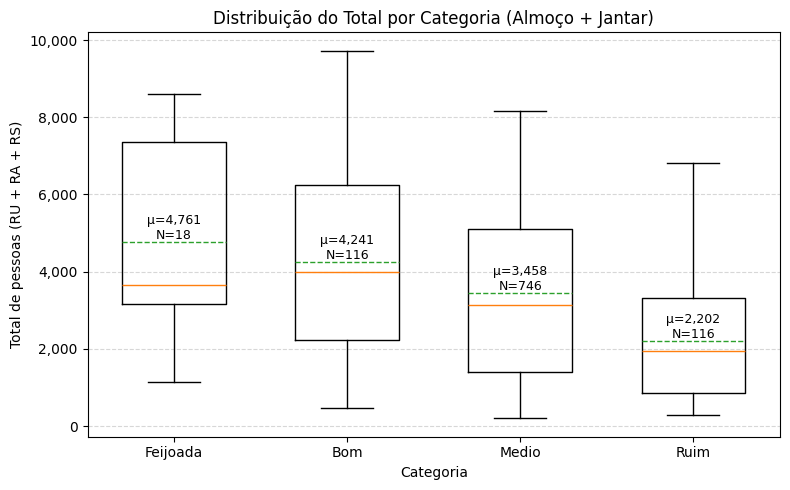

In [85]:
# Boxplot do TOTAL (RU+RA+RS) por categoria final
# Entrada: cardapio_clima_refeicoes_categorizado.xlsx (aba "dados")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

path = "cardapio_clima_refeicoes_categorizado.xlsx"  # gerado no passo anterior
df = pd.read_excel(path, sheet_name="dados")

# Garantias e limpeza
df["TOTAL"] = pd.to_numeric(df["TOTAL"], errors="coerce")
df = df.dropna(subset=["categoria_final", "TOTAL"])
df = df[df["TOTAL"] > 0]

# Ordem desejada das categorias
ordem = ["feijoada", "bom", "medio", "ruim"]
presentes = [c for c in ordem if c in df["categoria_final"].unique()]

# Séries por categoria
series = [df.loc[df["categoria_final"] == c, "TOTAL"].values for c in presentes]

# Plot
plt.figure(figsize=(8, 5))
bp = plt.boxplot(
    series,
    labels=[c.capitalize() for c in presentes],
    showmeans=True,
    meanline=True,
    widths=0.6
)
plt.title("Distribuição do Total por Categoria (Almoço + Jantar)")
plt.xlabel("Categoria")
plt.ylabel("Total de pessoas (RU + RA + RS)")

ax = plt.gca()
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Anotar a média (μ) e N em cada box
for i, c in enumerate(presentes, start=1):
    vals = series[i-1]
    if len(vals) == 0:
        continue
    y = np.mean(vals)
    n = len(vals)
    plt.text(i, y, f"μ={y:,.0f}\nN={n}", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


In [86]:
import pandas as pd, re
from unicodedata import normalize

CARD = "cardapio.xlsx"
COUNTS = "numero_refeicoes.xlsx"
OUT   = "refeicoes_cardapio_pessoas.csv"

# ---------- helpers ----------
def to_ascii_upper(s):
    if pd.isna(s): return ""
    s = normalize("NFKD", str(s)).encode("ascii","ignore").decode("ascii")
    return s.upper().strip()

def clean_cols(df):
    return {c: to_ascii_upper(c) for c in df.columns}

def find_col(df, norm_map, targets):
    for orig, norm in norm_map.items():
        for t in targets:
            if t == norm or t in norm: return orig
    return None

def pick_label(candidates, required_any, forbidden_any=None):
    forbidden_any = forbidden_any or []
    cand_norm = [to_ascii_upper(x) for x in candidates]
    for i, cn in enumerate(cand_norm):
        if any(req in cn for req in required_any) and not any(fbd in cn for fbd in forbidden_any):
            return candidates[i]
    return None

# classificação usada
PADROES = [
    (r"\bFEIJOADA\b", "feijoada"),
    (r"\b(ESTROGONOF|STROGONOFF|ESTROGONOFE)\b", "strogonoff"),
    (r"\b(LAGARTO)\b", "strogonoff"),
    (r"\bBIFE(S)?\b", "boi"),
    (r"(?=.*\b(SOBRECOXA|COXA)\b)", "frango_coxa"),
    (r"\bALMONDEGA DE FRANGO\b", "frango"),
    (r"\bALMONDEGA(S)?\b", "boi"),
    (r"\bCARNE(\s+BOVINA|\s+MOIDA)?\b", "boi"),
    (r"\b(BOVINO|BOVINA|BOVINOS|BOVINAS|BIFE|PATINHO|PICADINHO|ACEM|LAGARTO|POLPETONE|QUIBE|KIBE)\b", "boi"),
    (r"\b(SUINO|SUINA|SUINOS|SUINAS|LOMBO|BISTECA|PERNIL|PALETA|LINGUICA)\b", "porco"),
    (r"\b(FRANGO|SASSAMI|CHESTER)\b", "frango"),
    (r"\b(PEIXE|MERLUZA|PESCADA|TILAPIA)\b", "peixe"),
    (r"\b(OVO|STEAK|SALSICHA|NUGGETS)\b", "outro"),
]
def classificar_carne(prato: str) -> str:
    txt = to_ascii_upper(prato)
    for pat, classe in PADROES:
        if re.search(pat, txt): return classe
    return "outro"

# ---------- 1) CARDÁPIO ----------
card = pd.read_excel(CARD)
cmap = clean_cols(card)
c_date = find_col(card, cmap, ["DATE","DATA"])
c_refe = find_col(card, cmap, ["REFEICAO","REFEIÇÃO"])
c_prat = find_col(card, cmap, ["PRATO","ITEM","DESCRICAO","DESCRIÇÃO"])
if not all([c_date, c_refe, c_prat]):
    raise SystemExit("Não achei colunas de data/refeição/prato no cardápio.")
dfc = card[[c_date, c_refe, c_prat]].copy()
dfc.columns = ["date","refeicao","prato"]
dfc["date"] = pd.to_datetime(dfc["date"], errors="coerce").dt.normalize()

uniq = dfc["refeicao"].dropna().astype(str).unique().tolist()
alm_lab = pick_label(uniq, ["ALMOCO","ALMOCO - CARDAPIO","ALMOCO -"], ["VEG"]) or pick_label(uniq, ["ALMOCO"], [])
jan_lab = pick_label(uniq, ["JANTAR","JANTAR - CARDAPIO","JANTAR -"], ["VEG"]) or pick_label(uniq, ["JANTAR"], [])

menu_alm = dfc[dfc["refeicao"]==alm_lab].copy()
menu_jan = dfc[dfc["refeicao"]==jan_lab].copy()
menu_alm["meal"] = "ALMOÇO"
menu_jan["meal"] = "JANTAR"

menu = pd.concat([menu_alm, menu_jan], ignore_index=True).dropna(subset=["date"])
menu["classe"] = menu["prato"].map(classificar_carne)

# ---------- 2) CONTAGENS MultiIndex (ALMOÇO/JANTAR x RU/RA/RS/TOTAL) ----------
counts = pd.read_excel(COUNTS, header=[0,1])
dates = pd.to_datetime(counts.iloc[:,0], errors="coerce").dt.normalize()

def extract_block(tag_contains: str, meal_label: str) -> pd.DataFrame:
    cols = []
    for (c0,c1) in counts.columns:
        c0n, c1n = to_ascii_upper(c0), to_ascii_upper(c1)
        if (tag_contains in c0n) and (c1n in {"RU","RA","RS","TOTAL"}):
            cols.append((c0,c1))
    if not cols:
        return pd.DataFrame(columns=["date","meal","RU","RA","RS","TOTAL"])
    tmp = pd.DataFrame({"date": dates, "meal": meal_label})
    for (c0,c1) in cols:
        c1n = to_ascii_upper(c1)
        tmp[c1n] = pd.to_numeric(counts[(c0,c1)], errors="coerce")
    for u in ["RU","RA","RS"]:
        if u not in tmp.columns: tmp[u] = 0
    if "TOTAL" not in tmp.columns:
        tmp["TOTAL"] = tmp[["RU","RA","RS"]].sum(axis=1, min_count=1)
    return tmp[["date","meal","RU","RA","RS","TOTAL"]]

b_alm = extract_block("ALMOC", "ALMOÇO")   # cobre ALMOÇO/ALMOCO
b_jan = extract_block("JANT",  "JANTAR")
counts_wide = pd.concat([b_alm, b_jan], ignore_index=True).dropna(subset=["date"])

# ---------- 3) MERGE e salvar ----------
final = (menu.merge(counts_wide, on=["date","meal"], how="left")
              .fillna({"RU":0,"RA":0,"RS":0,"TOTAL":0})
              .astype({"RU":"int64","RA":"int64","RS":"int64","TOTAL":"int64"})
              .sort_values(["date","meal","classe","prato"])
              .reset_index(drop=True))

final.to_csv(OUT, index=False)

# ---------- 4) Sanity check e amostra ----------
gt0 = (final[["RU","RA","RS","TOTAL"]] > 0).sum()
print("Linhas totais:", len(final))
print("Linhas com valores > 0 ->", gt0.to_dict())
print("\nAmostra (TOTAL>0):")
display(final[final["TOTAL"]>0].head(10))
print("\nArquivo salvo em:", OUT)


Linhas totais: 1980
Linhas com valores > 0 -> {'RU': 743, 'RA': 722, 'RS': 913, 'TOTAL': 996}

Amostra (TOTAL>0):


,date,refeicao,prato,meal,classe,RU,RA,RS,TOTAL
949,2024-01-02,Almoço - Cardápio Padrão,STROGONOFF DE FRANGO,ALMOÇO,strogonoff,870,142,0,1012
950,2024-01-02,Jantar - Cardápio Padrão,"BIFE AO MOLHO ROTY (CALDO DE CARNE, MOLHO SHOY...",JANTAR,boi,400,50,0,450
951,2024-01-03,Almoço - Cardápio Padrão,PERNIL ASSADO AO MOLHO ESCURO (MOLHOS SHOYO E ...,ALMOÇO,porco,1069,207,0,1276
952,2024-01-03,Jantar - Cardápio Padrão,ISCAS DE FRANGO ACEBOLADO,JANTAR,frango,482,72,0,554
953,2024-01-04,Almoço - Cardápio Padrão,CARNE DE PANELA COM AZEITONA,ALMOÇO,boi,1177,208,0,1385
954,2024-01-04,Jantar - Cardápio Padrão,PERNIL SUÍNO AO MOLHO DE ABACAXI,JANTAR,porco,608,83,0,691
955,2024-01-05,Almoço - Cardápio Padrão,"CARNE ASSADA À ROMANESCA (PRESUNTO, ERVILHA E...",ALMOÇO,boi,1154,261,0,1415
956,2024-01-05,Jantar - Cardápio Padrão,CARNE EM CUBOS AO POMODORO,JANTAR,boi,478,71,0,549
957,2024-01-08,Almoço - Cardápio Padrão,BIFE AO MOLHO ROTY,ALMOÇO,boi,1503,356,0,1859
958,2024-01-08,Jantar - Cardápio Padrão,SALSICHA AO SUGO,JANTAR,outro,749,114,0,863



Arquivo salvo em: refeicoes_cardapio_pessoas.csv


In [87]:
final

,date,refeicao,prato,meal,classe,RU,RA,RS,TOTAL
0,2022-01-03,Almoço - Cardápio Padrão,QUIBE,ALMOÇO,boi,0,0,0,0
1,2022-01-03,Jantar - Cardápio Padrão,NUGGETS,JANTAR,outro,0,0,0,0
2,2022-01-04,Almoço - Cardápio Padrão,LINGUIÇA TOSCANA ACEBOLADA (CONTÉM CARNE SUÍNA),ALMOÇO,boi,0,0,0,0
3,2022-01-04,Jantar - Cardápio Padrão,QUIBE,JANTAR,boi,0,0,0,0
4,2022-01-05,Almoço - Cardápio Padrão,FRANGO ASSADO,ALMOÇO,frango,0,0,0,0
...,...,...,...,...,...,...,...,...,...
1975,2025-08-13,Jantar - Cardápio Padrão,BIFE AO SUGO,JANTAR,boi,0,0,0,0
1976,2025-08-14,Almoço - Cardápio Padrão,FRICASSÊ DE FRANGO,ALMOÇO,frango,0,0,0,0
1977,2025-08-14,Jantar - Cardápio Padrão,PESCADA AO MOLHO DE ERVAS,JANTAR,peixe,0,0,0,0
1978,2025-08-15,Almoço - Cardápio Padrão,"PUCHERO (CUBOS SUÍNO, LINGUIÇA CALABRESA, CENO...",ALMOÇO,porco,0,0,0,0


In [88]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Analisa cardápio x número de refeições (TOTAL = média da soma diária RU+RA+RS).
Gera:
- medias_almoco_total.csv / medias_jantar_total.csv (média da soma diária por carne)
- medias_almoco_total.png / medias_jantar_total.png
- medias_almoco_por_restaurante.csv / medias_jantar_por_restaurante.csv
- medias_almoco_<UNIDADE>.png / medias_jantar_<UNIDADE>.png

Como usar: coloque "cardapio.xlsx" e "numero_refeicoes.xlsx" na mesma pasta e rode:
    python analisa_cardapio_v3.py
"""

import pandas as pd, numpy as np, re, sys
from pathlib import Path
from unicodedata import normalize
import matplotlib.pyplot as plt

CARDAPIO_PATH = Path("cardapio.xlsx")
REFEICOES_PATH = Path("numero_refeicoes.xlsx")

def to_ascii_upper(s):
    if pd.isna(s): return ""
    s = normalize("NFKD", str(s)).encode("ascii","ignore").decode("ascii")
    return s.upper().strip()

def maybe_promote_first_row_to_header(df):
    if df.empty: return df, False
    col_names = [str(c) for c in df.columns]
    many_default = sum([cn.startswith("Unnamed") or cn.isdigit() for cn in col_names]) >= max(2, len(col_names)//2)
    first_row_str_ratio = (df.iloc[0].apply(lambda x: isinstance(x, str)).mean())
    if many_default and first_row_str_ratio >= 0.5:
        new = df.copy()
        new.columns = new.iloc[0]
        new = new.iloc[1:].reset_index(drop=True)
        return new, True
    return df, False

def clean_cols(df): return {c: to_ascii_upper(c) for c in df.columns}

def find_col(df, norm_map, targets):
    for orig, norm in norm_map.items():
        for t in targets:
            if t == norm or t in norm: return orig
    return None

def pick_label(candidates, required_any, forbidden_any=None):
    forbidden_any = forbidden_any or []
    cand_norm = [to_ascii_upper(x) for x in candidates]
    for i, cn in enumerate(cand_norm):
        if any(req in cn for req in required_any) and not any(fbd in cn for fbd in forbidden_any):
            return candidates[i]
    return None

PADROES = [
    (r"\bALMONDEGA DE FRANGO\b", "frango"),
    (r"\bLAGARTO\b", "lagarto"),
    (r"\bALMONDEGA(S)?\b", "boi"),
    (r"\bBIFE(S)?\b", "boi"),
    (r"\bCARNE(\s+BOVINA|\s+MOIDA)?\b", "boi"),
    (r"\b(BOVINO|BOVINA|BIFE|PATINHO|PICADINHO|ACEM|LAGARTO|POLPETONE|QUIBE|KIBE)\b", "boi"),
    (r"\b(SUINO|SUINA|LOMBO|BISTECA|PERNIL|PALETA|LINGUICA)\b", "porco"),
    (r"\b(FRANGO|SASSAMI|SOBRECOXA|CHESTER)\b", "frango"),
    (r"\b(PEIXE|MERLUZA|PESCADA|TILAPIA)\b", "peixe"),
    (r"\b(OVO|STEAK|SALSICHA|NUGGETS)\b", "outro"),
    (r"\bFEIJOADA\b", "feijoada"),
]
def classificar_carne(prato: str) -> str:
    txt = to_ascii_upper(prato)
    for pat, classe in PADROES:
        if re.search(pat, txt): return classe
    return "outro"

def detect_meal_cols(map_norm, keys):
    found = {"RU":None,"RA":None,"RS":None}
    for orig, norm in map_norm.items():
        for u in ["RU","RA","RS"]:
            if u in norm and any(k in norm for k in keys) and found[u] is None:
                found[u] = orig
    return found

def fallback_cols(ref_cols_map):
    found = {"RU":None,"RA":None,"RS":None}
    for orig, norm in ref_cols_map.items():
        for u in ["RU","RA","RS"]:
            if u==norm or (u in norm and found[u] is None):
                found[u]=orig
    return found

def safe_merge_counts(base_df, counts_df, cols_dict):
    cols_present = {k:v for k,v in cols_dict.items() if v is not None and v in counts_df.columns}
    if not cols_present: return pd.DataFrame(columns=["date","unidade","pessoas","carne"])
    tmp = counts_df[["date"] + list(cols_present.values())].copy()
    tmp.rename(columns={v:k for k,v in cols_present.items()}, inplace=True)
    value_vars = [c for c in ["RU","RA","RS"] if c in tmp.columns]
    tmp_long = pd.melt(tmp, id_vars=["date"], value_vars=value_vars, var_name="unidade", value_name="pessoas")
    tmp_long["pessoas"] = pd.to_numeric(tmp_long["pessoas"], errors="coerce").fillna(0)
    merged = tmp_long.merge(base_df, on="date", how="left")
    merged = merged.dropna(subset=["carne"])
    merged = merged[merged["pessoas"] > 0]
    return merged

def salva_total_soma_diaria(df_long, titulo, csv_out, png_out):
    if df_long.empty: return None
    daily_sum = df_long.groupby(["carne","date"])["pessoas"].sum().reset_index(name="pessoas_total_dia")
    medias = daily_sum.groupby("carne")["pessoas_total_dia"].mean().sort_values(ascending=False).round(1)
    medias.to_csv(csv_out, header=["media_pessoas_total_dia"])
    ax = medias.plot(kind="bar", figsize=(8,5), title=titulo)
    ax.set_xlabel("carne"); ax.set_ylabel("pessoas (média da soma diária)")
    plt.tight_layout(); plt.savefig(png_out, dpi=120); plt.close()
    return medias

def salva_por_restaurante(df_long, titulo_prefixo, csv_out, png_prefixo):
    if df_long.empty: return None
    pivot = (df_long.groupby(["unidade","carne"])["pessoas"].mean().round(1).unstack(fill_value=0).sort_index())
    pivot.to_csv(csv_out)
    for unidade in pivot.index:
        s = pivot.loc[unidade].sort_values(ascending=False)
        ax = s.plot(kind="bar", figsize=(8,5), title=f"{titulo_prefixo} — {unidade}")
        ax.set_xlabel("carne"); ax.set_ylabel("pessoas (média por unidade)")
        plt.tight_layout(); plt.savefig(f"{png_prefixo}_{unidade}.png", dpi=120); plt.close()
    return pivot

if __name__ == "__main__":
    # --- ler arquivos
    if not CARDAPIO_PATH.exists(): raise SystemExit("cardapio.xlsx não encontrado")
    if not REFEICOES_PATH.exists(): raise SystemExit("numero_refeicoes.xlsx não encontrado")
    cardapio = pd.read_excel(CARDAPIO_PATH)
    refeicoes = pd.read_excel(REFEICOES_PATH)
    refeicoes2, _ = maybe_promote_first_row_to_header(refeicoes)

    # --- cardápio
    card_cols_map = clean_cols(cardapio)
    date_col_c = find_col(cardapio, card_cols_map, ["DATE","DATA"])
    refeicao_col_c = find_col(cardapio, card_cols_map, ["REFEICAO","REFEIÇÃO"])
    prato_col_c = find_col(cardapio, card_cols_map, ["PRATO","ITEM","DESCRICAO","DESCRIÇÃO"])
    if not all([date_col_c, refeicao_col_c, prato_col_c]):
        raise SystemExit("Não encontrei as colunas 'date'/'refeicao'/'prato' em cardapio.xlsx")
    dfc = cardapio[[date_col_c, refeicao_col_c, prato_col_c]].copy()
    dfc.columns = ["date","refeicao","prato"]
    dfc["date"] = pd.to_datetime(dfc["date"], errors="coerce")

    uniq = dfc["refeicao"].dropna().astype(str).unique().tolist()
    alm_lab = pick_label(uniq, ["ALMOCO","ALMOCO - CARDAPIO","ALMOCO -"], ["VEG"]) or pick_label(uniq, ["ALMOCO"], [])
    jan_lab = pick_label(uniq, ["JANTAR","JANTAR - CARDAPIO","JANTAR -"], ["VEG"]) or pick_label(uniq, ["JANTAR"], [])
    df_alm = dfc[dfc["refeicao"]==alm_lab][["date","prato"]].copy() if alm_lab else pd.DataFrame(columns=["date","prato"])
    df_jan = dfc[dfc["refeicao"]==jan_lab][["date","prato"]].copy() if jan_lab else pd.DataFrame(columns=["date","prato"])
    for d in (df_alm, df_jan):
        if not d.empty:
            d["carne"] = d["prato"].map(classificar_carne)
            d.drop(columns=["prato"], inplace=True)
            d["date"] = pd.to_datetime(d["date"], errors="coerce")
            d.query("date >= '2024-01-01'", inplace=True)
            d.sort_values("date", inplace=True, ignore_index=True)

    # --- contagens
    ref_cols_map = clean_cols(refeicoes2)
    date_guess = pd.to_datetime(refeicoes2.iloc[:,0], errors="coerce")
    date_col_r = refeicoes2.columns[0] if not date_guess.isna().all() else next((c for c,n in ref_cols_map.items() if "DATA" in n or "DATE" in n), refeicoes2.columns[0])
    refeicoes2 = refeicoes2.rename(columns={date_col_r:"date"})
    refeicoes2["date"] = pd.to_datetime(refeicoes2["date"], errors="coerce")

    alm_cols = detect_meal_cols(ref_cols_map, ["ALMO","ALMOCO"]) or {}
    jan_cols = detect_meal_cols(ref_cols_map, ["JANT","JANTAR"]) or {}
    if not any(alm_cols.values()): alm_cols = fallback_cols(ref_cols_map)
    if not any(jan_cols.values()): jan_cols = alm_cols.copy()

    alm_long = safe_merge_counts(df_alm, refeicoes2, alm_cols)
    jan_long = safe_merge_counts(df_jan, refeicoes2, jan_cols)

    # --- saídas
    _ = salva_total_soma_diaria(alm_long, "Média (soma diária RU+RA+RS) por 'carne' — Almoço",
                                "medias_almoco_total.csv","medias_almoco_total.png")
    _ = salva_total_soma_diaria(jan_long, "Média (soma diária RU+RA+RS) por 'carne' — Jantar",
                                "medias_jantar_total.csv","medias_jantar_total.png")
    _ = salva_por_restaurante(alm_long, "Média por 'carne' (Almoço)",
                              "medias_almoco_por_restaurante.csv","medias_almoco")
    _ = salva_por_restaurante(jan_long, "Média por 'carne' (Jantar)",
                              "medias_jantar_por_restaurante.csv","medias_jantar")
    print("OK")


OK


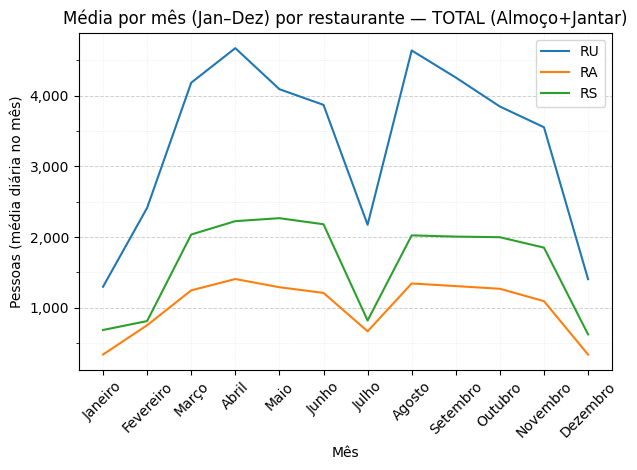

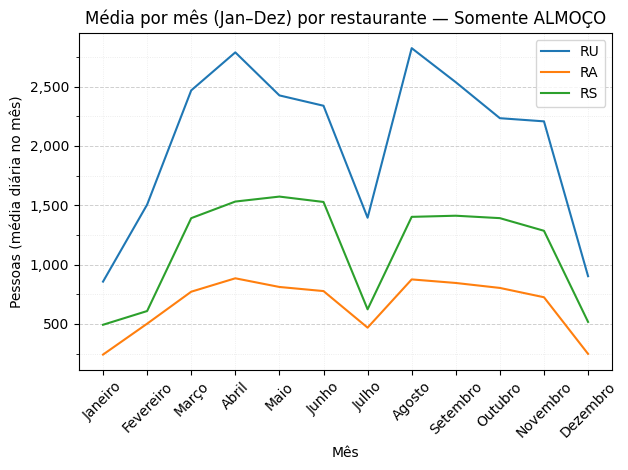

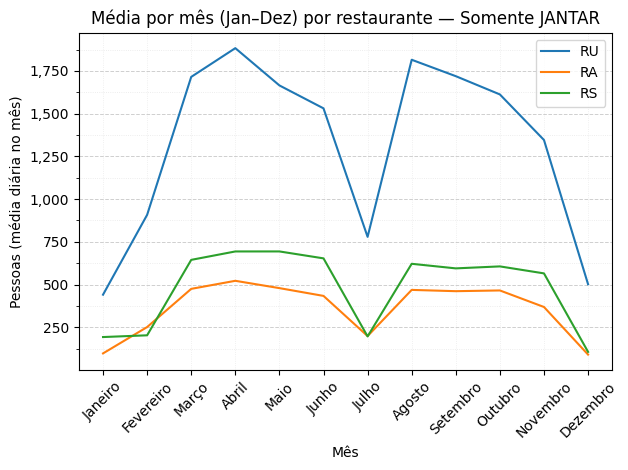

In [89]:
# Gráfico: média por mês (Jan–Dez) por restaurante
# 1) TOTAL (Almoço+Jantar)  2) Somente ALMOÇO  3) Somente JANTAR

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import AutoMinorLocator

# ==> garanta que "numero_refeicoes.xlsx" está no diretório atual do Colab
path = "numero_refeicoes.xlsx"

# a planilha tem cabeçalho em 2 linhas (ALMOÇO/JANTAR e RU/RA/RS)
counts = pd.read_excel(path, header=[0, 1])

# coluna de datas é a 1ª; parse para datetime
date = pd.to_datetime(counts.iloc[:, 0], errors="coerce")

# helper seguro (se não achar a coluna, devolve zeros)
def safe_get(top, sub):
    try:
        s = counts[(top, sub)]
    except Exception:
        s = pd.Series(0, index=counts.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce").fillna(0)

# ---- Séries por refeição ----
# ALMOÇO
RU_alm = safe_get("ALMOÇO", "RU")
RA_alm = safe_get("ALMOÇO", "RA")
RS_alm = safe_get("ALMOÇO", "RS")
# JANTAR
RU_jan = safe_get("JANTAR", "RU")
RA_jan = safe_get("JANTAR", "RA")
RS_jan = safe_get("JANTAR", "RS")

# ---- DataFrames base ----
df_tot = pd.DataFrame({
    "date": date,
    "RU_total_dia": RU_alm + RU_jan,
    "RA_total_dia": RA_alm + RA_jan,
    "RS_total_dia": RS_alm + RS_jan,
}).dropna(subset=["date"])

df_alm = pd.DataFrame({
    "date": date,
    "RU_alm_dia": RU_alm,
    "RA_alm_dia": RA_alm,
    "RS_alm_dia": RS_alm,
}).dropna(subset=["date"])

df_jan = pd.DataFrame({
    "date": date,
    "RU_jan_dia": RU_jan,
    "RA_jan_dia": RA_jan,
    "RS_jan_dia": RS_jan,
}).dropna(subset=["date"])

# ---- Agrupar por mês do calendário (ignora o ano) ----
def monthly_mean(df, cols):
    m = df.copy()
    m["month_num"] = m["date"].dt.month
    m = (m.groupby("month_num")[cols].mean().round(1)
           .reindex(range(1, 13)))  # garante jan..dez
    return m

monthly_tot = monthly_mean(df_tot, ["RU_total_dia", "RA_total_dia", "RS_total_dia"])
monthly_alm = monthly_mean(df_alm, ["RU_alm_dia", "RA_alm_dia", "RS_alm_dia"])
monthly_jan = monthly_mean(df_jan, ["RU_jan_dia", "RA_jan_dia", "RS_jan_dia"])

# ---- Função de plot com grid e rótulos ----
mes_labels = {
    1:"Janeiro", 2:"Fevereiro", 3:"Março", 4:"Abril", 5:"Maio", 6:"Junho",
    7:"Julho", 8:"Agosto", 9:"Setembro", 10:"Outubro", 11:"Novembro", 12:"Dezembro"
}
x = np.arange(1, 13)

def plot_lines(monthly, series_cols, title):
    plt.figure()
    for col in series_cols:
        plt.plot(x, monthly[col].values, label=col.split("_")[0])  # RU/RA/RS no label

    plt.title(title)
    plt.xlabel("Mês")
    plt.ylabel("Pessoas (média diária no mês)")
    plt.xticks(ticks=x, labels=[mes_labels[i] for i in x], rotation=45)
    plt.legend()

    ax = plt.gca()
    # grade principal no eixo Y
    ax.grid(True, which="major", axis="y", linestyle="--", linewidth=0.7, alpha=0.6)
    # grade secundária (mais suave) no eixo Y
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, which="minor", axis="y", linestyle=":", linewidth=0.6, alpha=0.3)
    # formatação do eixo Y com separador de milhar
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    # linhas discretas no eixo X
    ax.grid(True, which="major", axis="x", linestyle=":", linewidth=0.6, alpha=0.25)

    plt.tight_layout()
    plt.show()

# ---- 1) TOTAL (Almoço+Jantar) ----
plot_lines(
    monthly_tot,
    ["RU_total_dia", "RA_total_dia", "RS_total_dia"],
    "Média por mês (Jan–Dez) por restaurante — TOTAL (Almoço+Jantar)"
)

# ---- 2) Somente ALMOÇO ----
plot_lines(
    monthly_alm,
    ["RU_alm_dia", "RA_alm_dia", "RS_alm_dia"],
    "Média por mês (Jan–Dez) por restaurante — Somente ALMOÇO"
)

# ---- 3) Somente JANTAR ----
plot_lines(
    monthly_jan,
    ["RU_jan_dia", "RA_jan_dia", "RS_jan_dia"],
    "Média por mês (Jan–Dez) por restaurante — Somente JANTAR"
)

# ---- opcional: salvar tabelas usadas nos 3 gráficos ----
monthly_tot.to_csv("medias_por_mes_jan_dez_total.csv", index_label="mes")
monthly_alm.to_csv("medias_por_mes_jan_dez_almoco.csv", index_label="mes")
monthly_jan.to_csv("medias_por_mes_jan_dez_jantar.csv", index_label="mes")


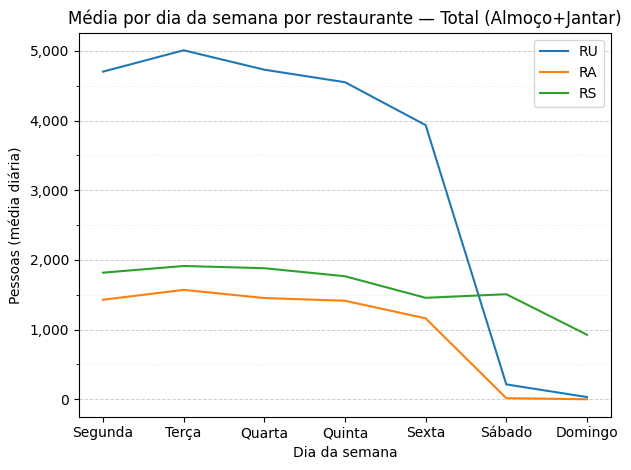

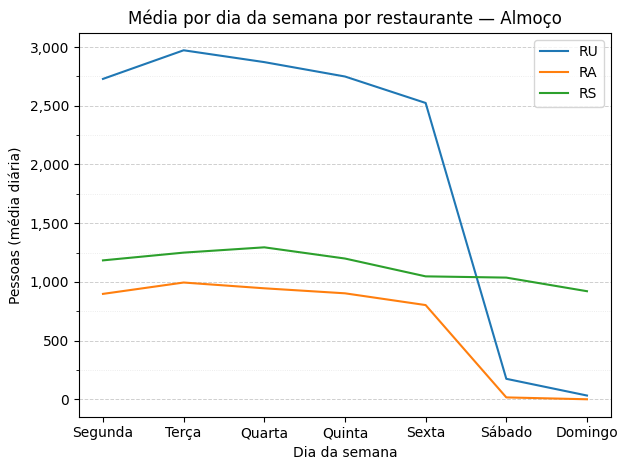

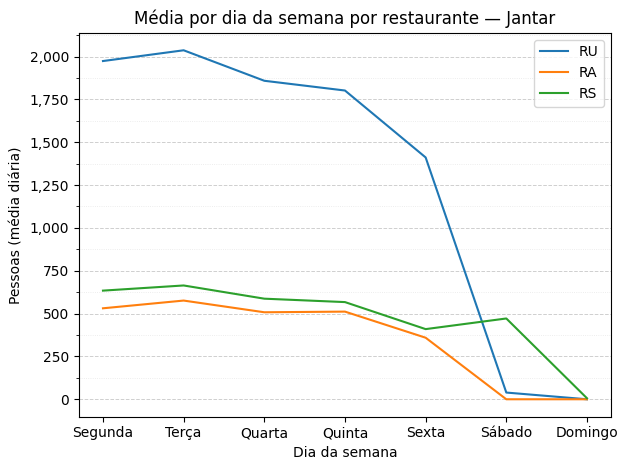

In [90]:
# Linhas por restaurante (x = dia da semana; y = média)
# 1) Total (Almoço+Jantar)  2) Almoço   3) Jantar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import AutoMinorLocator

# === Ler planilha com cabeçalho em 2 linhas (ALMOÇO/JANTAR e RU/RA/RS) ===
path = "numero_refeicoes.xlsx"  # certifique-se de que o arquivo está no diretório atual do Colab
counts = pd.read_excel(path, header=[0, 1])

# Datas (1ª coluna)
date = pd.to_datetime(counts.iloc[:, 0], errors="coerce")

# Helper seguro (retorna série numérica; se não achar a coluna, devolve zeros)
def safe_get(top, sub):
    try:
        s = counts[(top, sub)]
    except Exception:
        s = pd.Series(0, index=counts.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce").fillna(0)

# Séries por refeição
RU_alm = safe_get("ALMOÇO", "RU")
RA_alm = safe_get("ALMOÇO", "RA")
RS_alm = safe_get("ALMOÇO", "RS")

RU_jan = safe_get("JANTAR", "RU")
RA_jan = safe_get("JANTAR", "RA")
RS_jan = safe_get("JANTAR", "RS")

# Totais (Almoço + Jantar)
RU_tot = RU_alm + RU_jan
RA_tot = RA_alm + RA_jan
RS_tot = RS_alm + RS_jan

# DataFrame base
df = pd.DataFrame({
    "date": date,
    "RU_alm": RU_alm, "RA_alm": RA_alm, "RS_alm": RS_alm,
    "RU_jan": RU_jan, "RA_jan": RA_jan, "RS_jan": RS_jan,
    "RU_tot": RU_tot, "RA_tot": RA_tot, "RS_tot": RS_tot,
}).dropna(subset=["date"])

# Dia da semana (0=Segunda ... 6=Domingo)
df["weekday_num"] = df["date"].dt.weekday
weekday_order = list(range(7))
weekday_labels = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
x = np.arange(7)

def weekday_mean(df, cols):
    """Média por dia da semana para as colunas informadas."""
    return (df.groupby("weekday_num")[cols]
              .mean()
              .reindex(weekday_order)
              .round(1))

def plot_lines(wk_df, title):
    plt.figure()
    # Linhas por restaurante (ordem RU, RA, RS)
    for col in wk_df.columns:
        plt.plot(x, wk_df[col].values, label=col.split("_")[0])  # RU/RA/RS

    plt.title(title)
    plt.xlabel("Dia da semana")
    plt.ylabel("Pessoas (média diária)")
    plt.xticks(ticks=x, labels=weekday_labels, rotation=0)
    plt.legend()

    # Grid e formatação de milhares
    ax = plt.gca()
    ax.grid(True, which="major", axis="y", linestyle="--", linewidth=0.7, alpha=0.6)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, which="minor", axis="y", linestyle=":", linewidth=0.6, alpha=0.3)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

    plt.tight_layout()
    plt.show()

# 1) Total (Almoço+Jantar)
wk_total = weekday_mean(df, ["RU_tot", "RA_tot", "RS_tot"])
plot_lines(wk_total, "Média por dia da semana por restaurante — Total (Almoço+Jantar)")

# 2) Somente Almoço
wk_alm = weekday_mean(df, ["RU_alm", "RA_alm", "RS_alm"])
plot_lines(wk_alm, "Média por dia da semana por restaurante — Almoço")

# 3) Somente Jantar
wk_jan = weekday_mean(df, ["RU_jan", "RA_jan", "RS_jan"])
plot_lines(wk_jan, "Média por dia da semana por restaurante — Jantar")


In [23]:
# Gráficos de barras agrupadas: Não chuvoso × Chuvoso (≥1,0 mm) por restaurante
# 1) Total (Almoço+Jantar)  2) Somente Almoço  3) Somente Jantar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.ticker import AutoMinorLocator

# ----------------------
# 1) Ler arquivos
# ----------------------
rain_path = "dias_chuvosos_1mm.csv"
counts_path = "numero_refeicoes.xlsx"

# a) Dias chuvosos
rain = pd.read_csv(rain_path)
# normaliza data para 'date' (YYYY-MM-DD) e garante binária
rain["date"] = pd.to_datetime(rain["date"], errors="coerce").dt.date
rain["dia_chuvoso"] = rain["dia_chuvoso"].astype(int)

# b) Tabela de refeições (cabeçalho em 2 linhas: ALMOÇO/JANTAR + RU/RA/RS)
counts = pd.read_excel(counts_path, header=[0, 1])
date_col = pd.to_datetime(counts.iloc[:, 0], errors="coerce").dt.date

def safe_mi(top, sub):
    """Lê uma coluna MultiIndex (top, sub); se ausente, devolve zeros."""
    try:
        s = counts[(top, sub)]
    except Exception:
        s = pd.Series(0, index=counts.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce").fillna(0)

# Séries por refeição
RU_alm = safe_mi("ALMOÇO", "RU"); RA_alm = safe_mi("ALMOÇO", "RA"); RS_alm = safe_mi("ALMOÇO", "RS")
RU_jan = safe_mi("JANTAR", "RU"); RA_jan = safe_mi("JANTAR", "RA"); RS_jan = safe_mi("JANTAR", "RS")

base = pd.DataFrame({
    "date": date_col,
    # almoço
    "RU_alm": RU_alm, "RA_alm": RA_alm, "RS_alm": RS_alm,
    # jantar
    "RU_jan": RU_jan, "RA_jan": RA_jan, "RS_jan": RS_jan,
}).dropna(subset=["date"])

# agrega por dia (se houver linhas duplicadas por data)
daily = (base.groupby("date", as_index=False)
              .sum())

# totais (almoço + jantar)
daily["RU_tot"] = daily["RU_alm"] + daily["RU_jan"]
daily["RA_tot"] = daily["RA_alm"] + daily["RA_jan"]
daily["RS_tot"] = daily["RS_alm"] + daily["RS_jan"]

# junta com a marcação de chuva
df = daily.merge(rain[["date", "dia_chuvoso"]], on="date", how="inner")
# garante presença dos dois grupos
if set(df["dia_chuvoso"].unique()) != {0, 1}:
    raise ValueError("Faltam dias em um dos grupos (chuvoso ou não chuvoso). Verifique o CSV de chuva e as datas do Excel.")

# ----------------------
# 2) Funções utilitárias
# ----------------------
def group_means(df, cols):
    """Médias por grupo (0=Não chuvoso, 1=Chuvoso) nas colunas indicadas."""
    m = (df.groupby("dia_chuvoso")[cols].mean().round(1))
    # segurança para ordem do índice
    return m.reindex([0, 1])

def plot_grouped(means_df, title_prefix):
    labels_rest = ["RU", "RA", "RS"]  # ordem e rótulos no eixo X
    x = np.arange(len(labels_rest))
    width = 0.38

    # extrai séries nas colunas esperadas, mantendo ordem RU/RA/RS
    cols = means_df.columns.tolist()
    order_cols = [c for c in cols if any(c.startswith(k) for k in ["RU", "RA", "RS"])]
    # mapeia para RU/RA/RS
    def pick(prefix):
        return [c for c in order_cols if c.startswith(prefix)][0]

    y0 = means_df.loc[0, [pick("RU"), pick("RA"), pick("RS")]]
    y1 = means_df.loc[1, [pick("RU"), pick("RA"), pick("RS")]]

    # contagens por grupo para título
    n0 = int((df["dia_chuvoso"] == 0).sum())
    n1 = int((df["dia_chuvoso"] == 1).sum())

    plt.figure()
    bars0 = plt.bar(x - width/2, y0.values, width, label="Não chuvoso")
    bars1 = plt.bar(x + width/2, y1.values, width, label="Chuvoso (≥ 1,0 mm)")

    plt.title(f"{title_prefix}\nN não chuvoso={n0} · N chuvoso={n1}")
    plt.xlabel("Restaurante")
    plt.ylabel("Pessoas (média diária)")
    plt.xticks(ticks=x, labels=labels_rest)
    plt.legend()

    # Grid e formatação do eixo Y
    ax = plt.gca()
    ax.grid(True, which="major", axis="y", linestyle="--", linewidth=0.7, alpha=0.6)
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(True, which="minor", axis="y", linestyle=":", linewidth=0.6, alpha=0.3)
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

    # Anotar valores nas barras
    def annotate_bars(bar_container):
        for rect in bar_container:
            h = rect.get_height()
            ax.annotate(f"{h:,.0f}",
                        xy=(rect.get_x() + rect.get_width()/2, h),
                        xytext=(0, 3), textcoords="offset points",
                        ha="center", va="bottom", fontsize=9)
    annotate_bars(bars0)
    annotate_bars(bars1)

    plt.tight_layout()
    plt.show()

# ----------------------
# 3) GRÁFICOS
# ----------------------
# (a) TOTAL (almoço + jantar)
means_total = group_means(df, ["RU_tot", "RA_tot", "RS_tot"])
plot_grouped(means_total, "Média diária por restaurante — Não chuvoso vs Chuvoso (≥ 1,0 mm) — TOTAL")

# (b) Somente ALMOÇO
means_alm = group_means(df, ["RU_alm", "RA_alm", "RS_alm"])
plot_grouped(means_alm, "Média diária por restaurante — Não chuvoso vs Chuvoso (≥ 1,0 mm) — ALMOÇO")

# (c) Somente JANTAR
means_jan = group_means(df, ["RU_jan", "RA_jan", "RS_jan"])
plot_grouped(means_jan, "Média diária por restaurante — Não chuvoso vs Chuvoso (≥ 1,0 mm) — JANTAR")


FileNotFoundError: [Errno 2] No such file or directory: 'dias_chuvosos_1mm.csv'

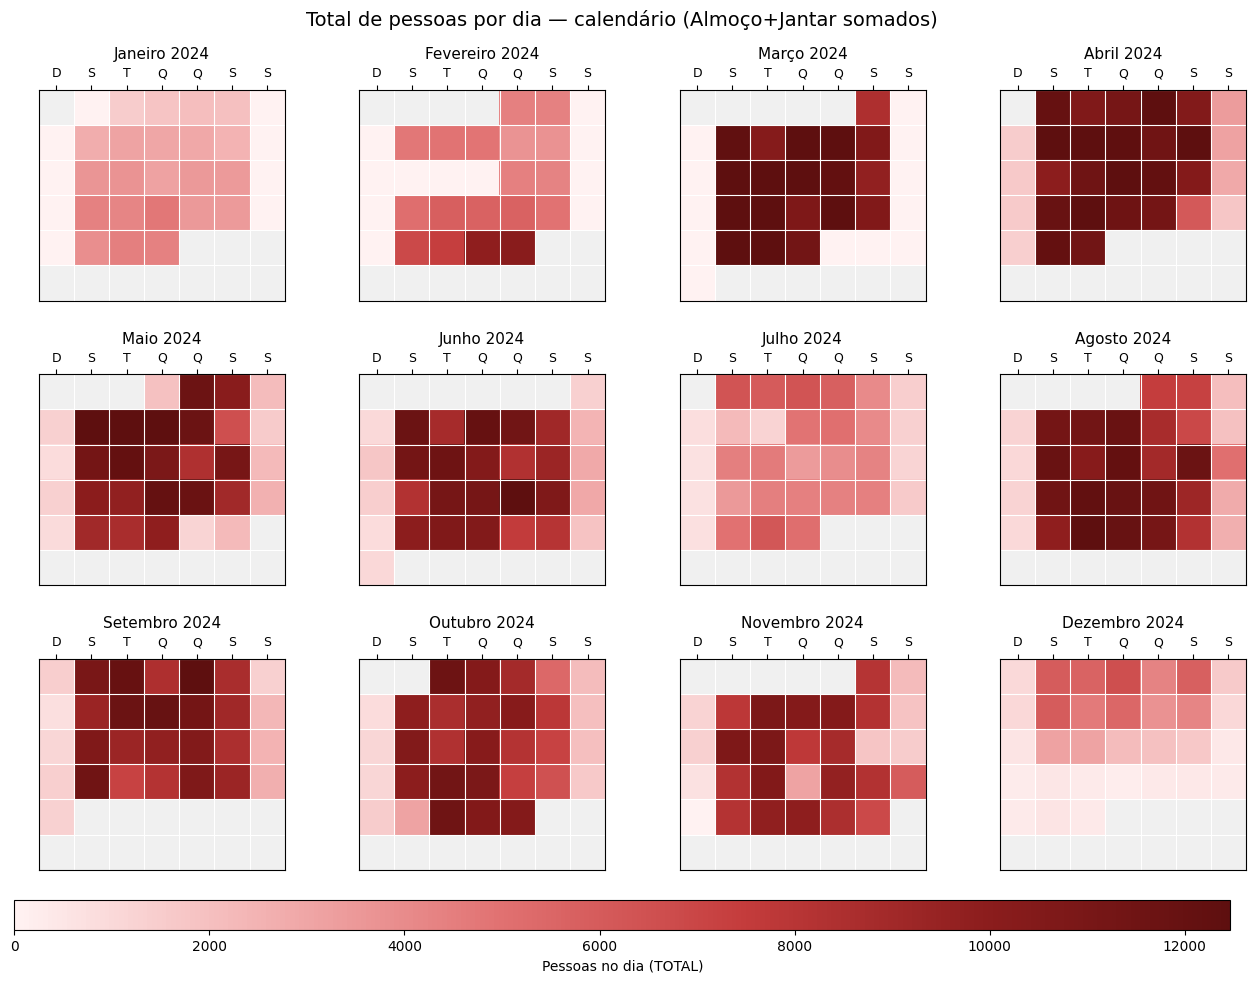

In [91]:
# Calendar heatmap (Jan–Dez) — TOTAL diário (RU+RA+RS, almoço+jantar)
# Tema de cores "Unicamp" (vermelhos), colorbar fora da grade.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import calendar
from datetime import date

# ===== Parâmetros =====
XLSX_PATH = "numero_refeicoes.xlsx"   # deixe no diretório atual
YEAR = 2024                           # ano a exibir
PCTL_MAX = 95                         # limita o topo da paleta (p95) p/ evitar outliers

# ===== Leitura e preparo =====
counts = pd.read_excel(XLSX_PATH, header=[0, 1])
dates = pd.to_datetime(counts.iloc[:, 0], errors="coerce")

def safe_get(top, sub):
    try:
        s = counts[(top, sub)]
    except Exception:
        s = pd.Series(0, index=counts.index, dtype="float64")
    return pd.to_numeric(s, errors="coerce").fillna(0)

# Almoço + Jantar por restaurante
RU_tot = safe_get("ALMOÇO", "RU") + safe_get("JANTAR", "RU")
RA_tot = safe_get("ALMOÇO", "RA") + safe_get("JANTAR", "RA")
RS_tot = safe_get("ALMOÇO", "RS") + safe_get("JANTAR", "RS")

df = (pd.DataFrame({"date": dates, "RU": RU_tot, "RA": RA_tot, "RS": RS_tot})
        .dropna(subset=["date"]))
df["ALL"] = df[["RU","RA","RS"]].sum(axis=1)
df["d"] = df["date"].dt.date
daily = df.groupby("d", as_index=False)["ALL"].sum()
daily = daily[(pd.to_datetime(daily["d"]).dt.year == YEAR)]
val = {d: v for d, v in daily.itertuples(index=False)}  # dict data->valor

# ===== Matriz mensal (padronizada p/ 6 semanas) =====
calendar.setfirstweekday(calendar.SUNDAY)  # D S T Q Q S S

def month_matrix(year, month, valdict, n_rows=6):
    """Retorna matriz (n_rows x 7) com valores por dia; completa com NaN no fim."""
    weeks = calendar.monthcalendar(year, month)  # lista de semanas (4–6)
    mat = np.full((n_rows, 7), np.nan, dtype="float")
    for i, wk in enumerate(weeks):
        for j, daynum in enumerate(wk):
            if daynum != 0:
                d = date(year, month, daynum)
                mat[i, j] = valdict.get(d, np.nan)
    return mat

mats = [month_matrix(YEAR, m, val, n_rows=6) for m in range(1, 13)]
all_vals = np.concatenate([m.ravel() for m in mats])
vmin = 0
vmax = np.nanpercentile(all_vals, PCTL_MAX) if np.isfinite(np.nanmax(all_vals)) else np.nanmax(all_vals)

# ===== Paleta "Unicamp" (rose -> vermelho -> bordô) =====
# ajuste as cores se quiser um tom mais claro/escuro
unicamp_reds = LinearSegmentedColormap.from_list(
    "unicamp_reds",
    [
        "#fff2f2",  # rose muito claro
        "#f3b3b3",  # rose
        "#e17171",  # vermelho claro
        "#c43c3c",  # vermelho médio
        "#8c1d1d",  # vermelho escuro
        "#5e0f0f",  # bordô
    ],
    N=256,
)
# dias sem dado: cinza claro
unicamp_reds.set_bad(color="#f0f0f0")

# ===== Plot (grade 3x4 com tamanhos iguais) =====
fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 4, hspace=0.35, wspace=0.15)

dow_labels = list("DSTQQSS")  # Domingo..Sábado
month_labels = ["Janeiro","Fevereiro","Março","Abril","Maio","Junho",
                "Julho","Agosto","Setembro","Outubro","Novembro","Dezembro"]

last_im = None
for m in range(1, 13):
    ax = fig.add_subplot(gs[(m-1)//4, (m-1)%4])
    mat = mats[m-1]
    last_im = ax.imshow(mat, aspect="equal", cmap=unicamp_reds, vmin=vmin, vmax=vmax)
    ax.set_title(f"{month_labels[m-1]} {YEAR}", fontsize=11, pad=6)

    # ticks do eixo X (dias da semana) no topo
    ax.set_xticks(range(7), labels=dow_labels, fontsize=9)
    ax.xaxis.tick_top()
    ax.set_yticks([])

    # linhas de grade brancas entre células
    ax.set_xticks(np.arange(-.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(-.5, mat.shape[0]+.5, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", length=0)

# espaço para o título e para a colorbar
fig.subplots_adjust(top=0.90, bottom=0.12)

# colorbar fora da grade (embaixo, centralizada)
cax = fig.add_axes([0.12, 0.06, 0.76, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(last_im, cax=cax, orientation="horizontal")
cbar.set_label("Pessoas no dia (TOTAL)")

fig.suptitle("Total de pessoas por dia — calendário (Almoço+Jantar somados)", fontsize=14)
plt.show()


**Tratamento dos dados para IA - Organização em DataFrame**

In [157]:
teste_1 = pd.read_excel("cardapio_clima_refeicoes_categorizado.xlsx")
#teste_1 = teste_1[["date", "categoria_final", "RU", "RS", "RA", "TOTAL"]]
teste_1 = teste_1[teste_1["date"] <= "2025-07-31"] # Remover linhas onde não temos dados.
teste_1 = teste_1[~(teste_1['RS'].isna() & teste_1['RA'].isna() & teste_1['RU'].isna())] # Remover linhas onde TODAS as colunas são NaN. São 7 dias. Não sei porque não existe esses dados.


# Estou tirando um outlier. Teve um dia com ovo e quase 7k de pessoas
teste_1 = teste_1[~(
    (teste_1['pratos'].str.contains(r'\bOVOS\b', case=False, na=False, regex=True)) &
    (teste_1['TOTAL'] > 6000)
)]


almoco_final_df = teste_1[(teste_1["meal"] == "ALMOÇO")]
janta_final_df = teste_1[(teste_1["meal"] == "JANTAR")]


### Organizando os dados em almoco e janta com DataFrame contendo dados de treino | dados de teste + TOTAL ###
# transformando categorias em 4 colunas
categoria_dummies = pd.get_dummies(almoco_final_df['categoria_final']).astype(int)# Criar as variáveis dummy e garantir que são inteiros
almoco_final_df = pd.concat([almoco_final_df, categoria_dummies], axis=1)# Juntar com o DataFrame original
almoco_final_df = almoco_final_df[["date", "feijoada", "bom", "medio", "ruim", "chuvoso_1mm", "RU", "RA", "RS", "TOTAL"]]

# transformando categorias em 4 colunas
categoria_dummies = pd.get_dummies(janta_final_df['categoria_final']).astype(int)# Criar as variáveis dummy e garantir que são inteiros
janta_final_df = pd.concat([janta_final_df, categoria_dummies], axis=1)# Juntar com o DataFrame original
janta_final_df = janta_final_df[["date", "feijoada", "bom", "medio", "ruim", "chuvoso_1mm", "RU", "RA", "RS", "TOTAL"]]
##############################################################################################################

### Organizando os dias do ano por grupos do tipo (ano - mes - dia da semana). Ou seja, não teremos mais o dia do mês ###
# Converter para datetime se necessário
almoco_final_df['date'] = pd.to_datetime(almoco_final_df['date'])
janta_final_df['date'] = pd.to_datetime(janta_final_df['date'])
# Criar nova coluna com formato "YYYY-MM-DiaDaSemana"
almoco_final_df['date'] = (almoco_final_df['date'].dt.strftime('%Y-%m-') +
                                  almoco_final_df['date'].dt.dayofweek.astype(str))
janta_final_df['date'] = (janta_final_df['date'].dt.strftime('%Y-%m-') +
                                  janta_final_df['date'].dt.dayofweek.astype(str))
##############################################################################################################


# Substituir NaN por 0 nas colunas RU, RA e RS
almoco_final_df[['RU', 'RA', 'RS']] = almoco_final_df[['RU', 'RA', 'RS']].fillna(0)
janta_final_df[['RU', 'RA', 'RS']] = janta_final_df[['RU', 'RA', 'RS']].fillna(0)

almoco_final_df['categoria_unica'] = (
    df['feijoada'] * 4 +
    df['bom'] * 3 +
    df['medio'] * 2 +
    df['ruim'] * 1
)
almoco_final_df = almoco_final_df[["date", "categoria_unica", "chuvoso_1mm", "RU", "RA", "RS", "TOTAL"]]

janta_final_df['categoria_unica'] = (
    df['feijoada'] * 4 +
    df['bom'] * 3 +
    df['medio'] * 2 +
    df['ruim'] * 1
)
janta_final_df = janta_final_df[["date", "categoria_unica", "chuvoso_1mm", "RU", "RA", "RS", "TOTAL"]]



almoco_final_df

,date,categoria_unica,chuvoso_1mm,RU,RA,RS,TOTAL
0,2024-01-1,3,0,870.0,142.0,0.0,1012.0
2,2024-01-2,2,1,1069.0,207.0,0.0,1276.0
4,2024-01-3,2,0,1177.0,208.0,0.0,1385.0
6,2024-01-4,2,0,1154.0,261.0,0.0,1415.0
8,2024-01-0,2,0,1503.0,356.0,0.0,1859.0
...,...,...,...,...,...,...,...
994,2025-07-6,2,0,0.0,0.0,799.0,799.0
995,2025-07-0,2,0,1509.0,625.0,422.0,2556.0
997,2025-07-1,2,0,1825.0,691.0,454.0,2970.0
999,2025-07-2,2,0,1931.0,628.0,514.0,3073.0


In [160]:
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns  # Adicionei esta linha

df = almoco_final_df

# Carregar e verificar os dados
print("=== ANÁLISE INICIAL DOS DADOS ===")
print(f"Shape do DataFrame: {df.shape}")
print("\nColunas:")
print(df.columns.tolist())
print("\nPrimeiras linhas:")
print(df.head())
print("\nEstatísticas descritivas:")
print(df.describe())

=== ANÁLISE INICIAL DOS DADOS ===
Shape do DataFrame: (540, 7)

Colunas:
['date', 'categoria_unica', 'chuvoso_1mm', 'RU', 'RA', 'RS', 'TOTAL']

Primeiras linhas:
        date  categoria_unica  chuvoso_1mm      RU     RA   RS   TOTAL
0  2024-01-1                3            0   870.0  142.0  0.0  1012.0
2  2024-01-2                2            1  1069.0  207.0  0.0  1276.0
4  2024-01-3                2            0  1177.0  208.0  0.0  1385.0
6  2024-01-4                2            0  1154.0  261.0  0.0  1415.0
8  2024-01-0                2            0  1503.0  356.0  0.0  1859.0

Estatísticas descritivas:
       categoria_unica  chuvoso_1mm           RU           RA           RS  \
count       540.000000   540.000000   540.000000   540.000000   540.000000   
mean          2.033333     0.077778  2133.155556   691.924074  1200.444444   
std           0.536947     0.268070  1681.209471   564.024907   613.621262   
min           1.000000     0.000000     0.000000     0.000000     0.00000

=== ANÁLISE INICIAL DOS DADOS ===
Shape do DataFrame: (540, 10)

Colunas:
['date', 'categoria_unica', 'chuvoso_1mm', 'RU', 'RA', 'RS', 'TOTAL', 'ano', 'mes', 'dia_semana']

Primeiras linhas:
        date  categoria_unica  chuvoso_1mm      RU     RA   RS   TOTAL   ano  \
0  2024-01-1                3            0   870.0  142.0  0.0  1012.0  2024   
2  2024-01-2                2            1  1069.0  207.0  0.0  1276.0  2024   
4  2024-01-3                2            0  1177.0  208.0  0.0  1385.0  2024   
6  2024-01-4                2            0  1154.0  261.0  0.0  1415.0  2024   
8  2024-01-0                2            0  1503.0  356.0  0.0  1859.0  2024   

   mes  dia_semana  
0    1           1  
2    1           2  
4    1           3  
6    1           4  
8    1           0  

=== PRÉ-PROCESSAMENTO ===
Valores missing:
date               0
categoria_unica    0
chuvoso_1mm        0
RU                 0
RA                 0
RS                 0
TOTAL              0
ano        

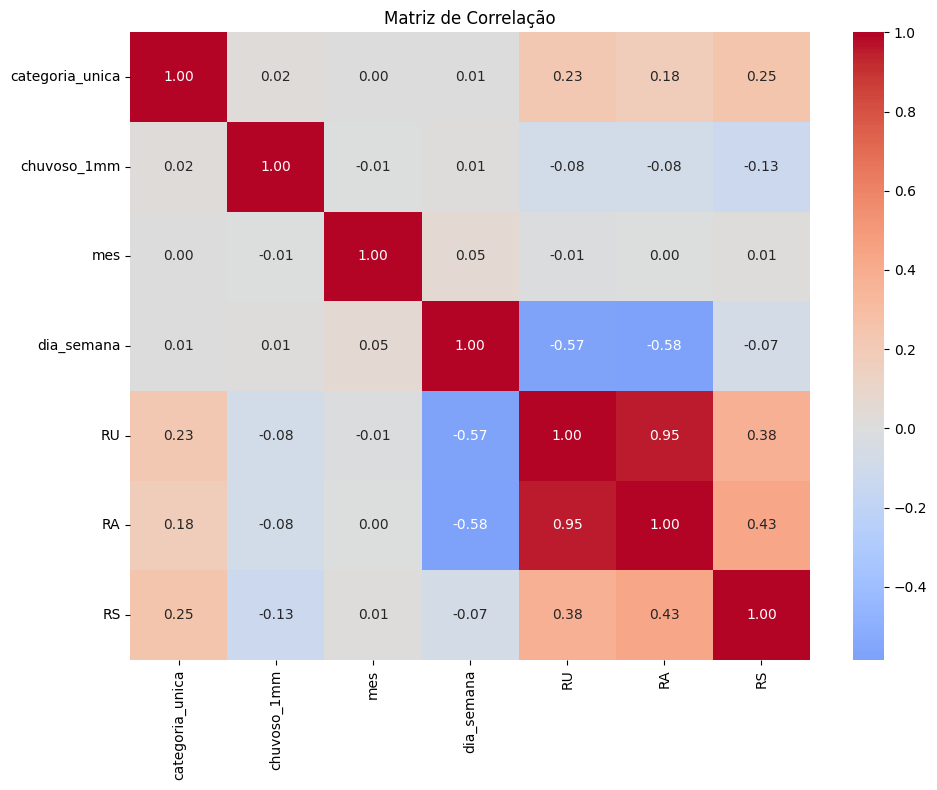


=== PREPARAÇÃO PARA MODELO ===
Treino: X(432, 4), y(432, 3)
Teste: X(108, 4), y(108, 3)
Normalização concluída

=== TREINANDO MODELO SVM ===
Modelo treinado com sucesso!

=== RESULTADOS - SVM Base ===

📊 RU:
   MAE: 833.3 pessoas
   RMSE: 1111.2 pessoas
   R²: 0.5281

📊 RA:
   MAE: 280.5 pessoas
   RMSE: 382.9 pessoas
   R²: 0.5111

📊 RS:
   MAE: 445.6 pessoas
   RMSE: 559.6 pessoas
   R²: 0.3075


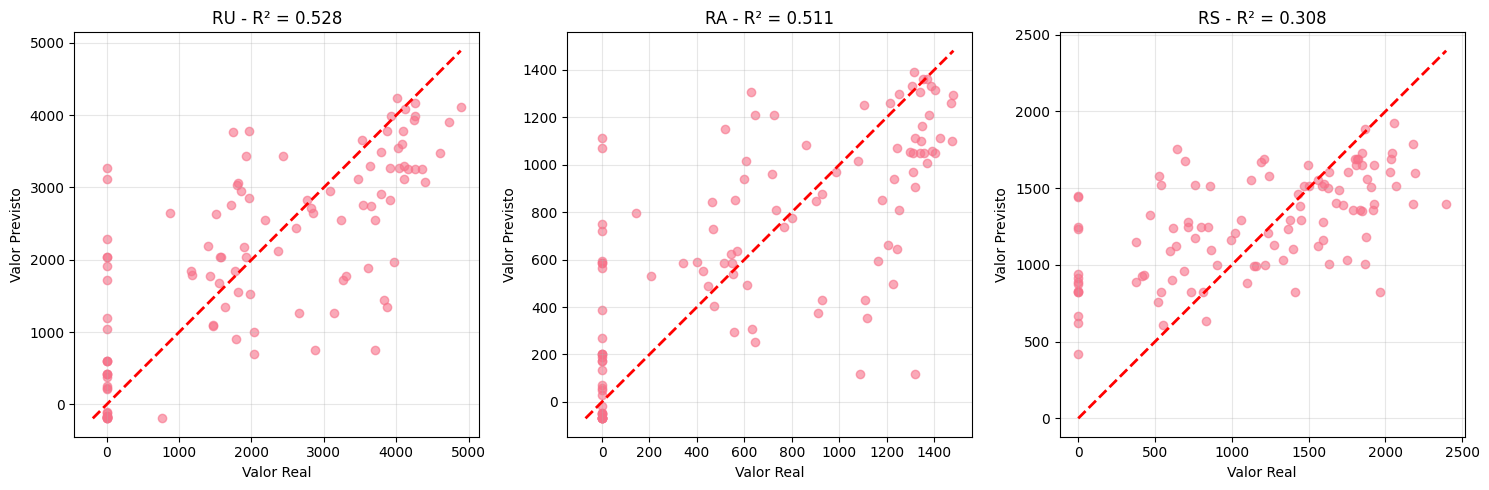


=== MODELO FINAL ===

=== EXEMPLO DE PREVISÃO ===
Previsão para Feijoada, Quarta-feira, Sem Chuva:
  RU: 3822 pessoas
  RA: 1220 pessoas
  RS: 1732 pessoas

🎯 RESUMO FINAL
📈 Performance Média:
   R²: 0.4489
   MAE: 519.8 pessoas
💡 Status: ❌ PRECISA MELHORAR


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [164]:
import pandas as pd
import numpy as np
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns  # Importação adicionada

# Configurar estilo dos gráficos
plt.style.use('default')
sns.set_palette("husl")

# 1. PREPARAÇÃO DOS DADOS
print("=== ANÁLISE INICIAL DOS DADOS ===")
print(f"Shape do DataFrame: {df.shape}")
print("\nColunas:")
print(df.columns.tolist())
print("\nPrimeiras linhas:")
print(df.head())

# 2. PRÉ-PROCESSAMENTO
print("\n=== PRÉ-PROCESSAMENTO ===")

# Verificar valores missing
print("Valores missing:")
print(df.isnull().sum())

# Tratar valores missing se necessário
df = df.dropna()
print(f"Shape após remover missing: {df.shape}")

# Extrair features temporais da coluna date
df['date'] = df['date'].astype(str)
df[['ano', 'mes', 'dia_semana']] = df['date'].str.split('-', expand=True)
df['ano'] = df['ano'].astype(int)
df['mes'] = df['mes'].astype(int)
df['dia_semana'] = df['dia_semana'].astype(int)

# Features finais
features = ['categoria_unica', 'chuvoso_1mm', 'mes', 'dia_semana']
X = df[features]
y = df[['RU', 'RA', 'RS']]

print(f"\nFeatures: {features}")
print(f"X shape: {X.shape}, y shape: {y.shape}")

# 3. ANÁLISE EXPLORATÓRIA
print("\n=== ANÁLISE EXPLORATÓRIA ===")

# Matriz de correlação
plt.figure(figsize=(10, 8))
correlation_matrix = pd.concat([X, y], axis=1).corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Matriz de Correlação')
plt.tight_layout()
plt.show()

# 4. DIVISÃO E NORMALIZAÇÃO
print("\n=== PREPARAÇÃO PARA MODELO ===")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

print(f"Treino: X{X_train.shape}, y{y_train.shape}")
print(f"Teste: X{X_test.shape}, y{y_test.shape}")

# Normalizar os dados
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("Normalização concluída")

# 5. MODELO SVM BASE
print("\n=== TREINANDO MODELO SVM ===")

modelo_svm = MultiOutputRegressor(
    SVR(kernel='rbf', C=1.0, epsilon=0.1)
)

modelo_svm.fit(X_train_scaled, y_train_scaled)

# Previsões
y_pred_scaled = modelo_svm.predict(X_test_scaled)
y_pred = scaler_y.inverse_transform(y_pred_scaled)

print("Modelo treinado com sucesso!")

# 6. AVALIAÇÃO
def avaliar_modelo(y_test, y_pred, modelo_nome="SVM"):
    alvos = ['RU', 'RA', 'RS']
    resultados = {}

    print(f"\n=== RESULTADOS - {modelo_nome} ===")

    for i, alvo in enumerate(alvos):
        mae = mean_absolute_error(y_test.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred[:, i]))
        r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])

        resultados[alvo] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}

        print(f"\n📊 {alvo}:")
        print(f"   MAE: {mae:.1f} pessoas")
        print(f"   RMSE: {rmse:.1f} pessoas")
        print(f"   R²: {r2:.4f}")

    return resultados

resultados_base = avaliar_modelo(y_test, y_pred, "SVM Base")

# 7. VISUALIZAÇÃO SIMPLES
def plot_resultados_simples(y_test, y_pred, resultados):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    alvos = ['RU', 'RA', 'RS']

    for i, alvo in enumerate(alvos):
        axes[i].scatter(y_test[alvo], y_pred[:, i], alpha=0.6)
        min_val = min(y_test[alvo].min(), y_pred[:, i].min())
        max_val = max(y_test[alvo].max(), y_pred[:, i].max())
        axes[i].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2)
        axes[i].set_xlabel('Valor Real')
        axes[i].set_ylabel('Valor Previsto')
        axes[i].set_title(f'{alvo} - R² = {resultados[alvo]["R2"]:.3f}')
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_resultados_simples(y_test, y_pred, resultados_base)

# 8. MODELO FINAL E PREVISÕES
print("\n=== MODELO FINAL ===")

# Usar o modelo base ou otimizar se necessário
modelo_final = modelo_svm

def prever_volumetria(categoria_unica, chuvoso_1mm, mes, dia_semana):
    input_data = np.array([[categoria_unica, chuvoso_1mm, mes, dia_semana]])
    input_scaled = scaler_X.transform(input_data)
    pred_scaled = modelo_final.predict(input_scaled)
    pred = scaler_y.inverse_transform(pred_scaled)

    return {
        'RU': max(0, pred[0][0]),
        'RA': max(0, pred[0][1]),
        'RS': max(0, pred[0][2])
    }

# Exemplo
print("\n=== EXEMPLO DE PREVISÃO ===")
exemplo = prever_volumetria(
    categoria_unica=4,  # feijoada
    chuvoso_1mm=0,      # não chuvoso
    mes=6,
    dia_semana=2        # quarta-feira
)

print("Previsão para Feijoada, Quarta-feira, Sem Chuva:")
for alvo, valor in exemplo.items():
    print(f"  {alvo}: {valor:.0f} pessoas")

# 9. RESUMO FINAL
print("\n" + "="*50)
print("🎯 RESUMO FINAL")
print("="*50)

r2_medio = np.mean([r['R2'] for r in resultados_base.values()])
mae_medio = np.mean([r['MAE'] for r in resultados_base.values()])

print(f"📈 Performance Média:")
print(f"   R²: {r2_medio:.4f}")
print(f"   MAE: {mae_medio:.1f} pessoas")

if r2_medio > 0.7:
    status = "✅ EXCELENTE"
elif r2_medio > 0.5:
    status = "⚠️  RAZOÁVEL"
else:
    status = "❌ PRECISA MELHORAR"

print(f"💡 Status: {status}")